# 02 · Psicometría y descripción de la muestra

Fiabilidad de los índices, relación estrés-bienestar y qué experiencias prefieren las personas.
Los índices son ítems propios inspirados en PSS (P3-P4), síntomas de tensión (P5) y WHO-5 (P6): se analizan como puntajes continuos, **sin puntos de corte ni categorías clínicas**.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2, ETIQUETAS_PREF, ETIQUETAS_W
aplicar_estilo()
pd.set_option('display.max_columns', 50)

In [2]:
from encuesta_etl import OUT_DEFAULT, PREFERENCIAS, P5, P6
df = pd.read_csv(OUT_DEFAULT)
print('n =', len(df))

def alfa_cronbach(items: pd.DataFrame) -> float:
    items = items.dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))

estres_items = pd.concat([df[['p3', 'p4']] / 4, df[P5] / 3], axis=1)
fiab = pd.DataFrame({
    'escala': ['Estrés (P3, P4, P5a-d)', 'Tensión (P5a-d)', 'Bienestar (P6a-d)'],
    'items': [6, 4, 4],
    'alfa': [alfa_cronbach(estres_items), alfa_cronbach(df[P5]), alfa_cronbach(df[P6])],
    'casos_completos': [len(estres_items.dropna()), len(df[P5].dropna()), len(df[P6].dropna())],
}).round(3)
fiab

n = 137


,escala,items,alfa,casos_completos
0,"Estrés (P3, P4, P5a-d)",6,0.849,122
1,Tensión (P5a-d),4,0.821,122
2,Bienestar (P6a-d),4,0.770,123


## Distribución de los índices

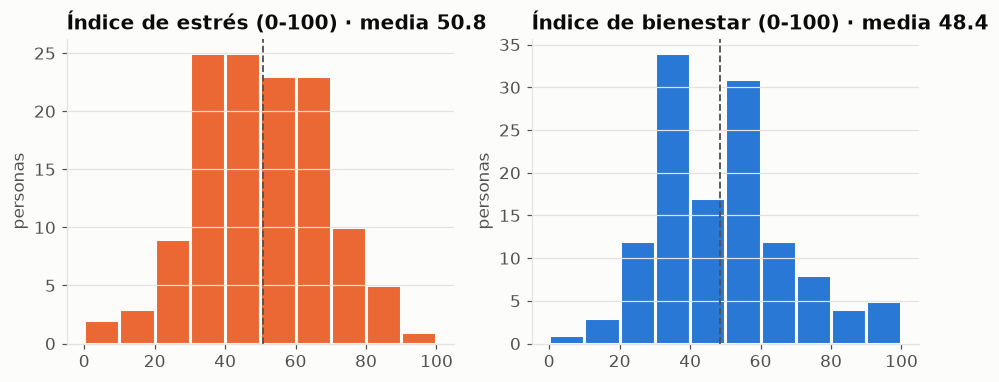

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, color, titulo in [(axes[0], 'estres_0_100', SERIES[1], 'Índice de estrés (0-100)'),
                               (axes[1], 'bienestar_0_100', SERIES[0], 'Índice de bienestar (0-100)')]:
    ax.hist(df[col].dropna(), bins=np.arange(0, 105, 10), color=color, edgecolor='#fcfcfb', linewidth=2)
    ax.axvline(df[col].mean(), color=TEXTO_2, linewidth=1.2, linestyle='--')
    ax.set_title(f'{titulo} · media {df[col].mean():.1f}')
    ax.set_ylabel('personas'); ax.grid(axis='x', visible=False)
guardar(fig, '02_distribucion_indices');

## Correlaciones (Spearman)

In [4]:
corr = df[['estres_0_100', 'tension_0_100', 'bienestar_0_100', 'satisfaccion', 'edad_ord']].corr(method='spearman').round(2)
corr

,estres_0_100,tension_0_100,bienestar_0_100,satisfaccion,edad_ord
estres_0_100,1.00,0.96,-0.47,-0.55,-0.32
tension_0_100,0.96,1.00,-0.41,-0.54,-0.36
bienestar_0_100,-0.47,-0.41,1.00,0.36,0.03
satisfaccion,-0.55,-0.54,0.36,1.00,0.32
edad_ord,-0.32,-0.36,0.03,0.32,1.00


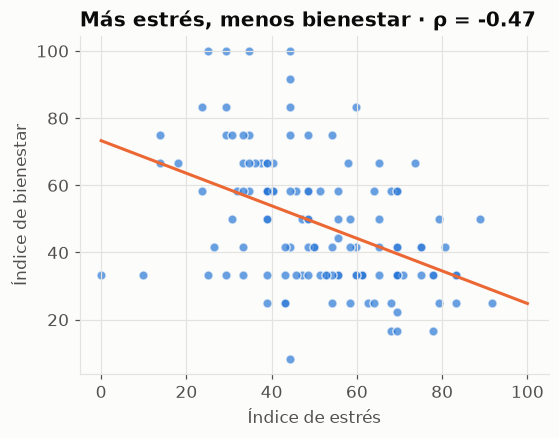

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4))
d = df.dropna(subset=['estres_0_100', 'bienestar_0_100'])
ax.scatter(d['estres_0_100'], d['bienestar_0_100'], s=36, color=SERIES[0], alpha=0.7, edgecolor='#fcfcfb', linewidth=1)
m, b = np.polyfit(d['estres_0_100'], d['bienestar_0_100'], 1)
x = np.array([0, 100]); ax.plot(x, m * x + b, color=SERIES[1], linewidth=2)
ax.set_xlabel('Índice de estrés'); ax.set_ylabel('Índice de bienestar')
ax.set_title(f"Más estrés, menos bienestar · ρ = {corr.loc['estres_0_100', 'bienestar_0_100']}")
guardar(fig, '02_estres_vs_bienestar');

## Cifras corregidas para el protocolo

In [6]:
frecuente = (df['p3'] >= 3)
cifras = {
    'Se sintió estresado(a) frecuente o muy frecuentemente (P3)': f"{frecuente.mean():.1%}",
    '…de ellos, de 18 a 24 años': f"{(df.loc[frecuente, 'edad_ord'] == 1).mean():.1%}",
    'Personas de 18 a 24 años en toda la muestra': f"{(df['edad_ord'] == 1).mean():.1%}",
    'Al menos uno: cansancio, tensión muscular o problemas de sueño (P7)': f"{df[['sint_cansancio', 'sint_tension_muscular', 'sint_sueno']].max(axis=1).mean():.1%}",
    'Eligió naturaleza o relajación (P10)': f"{df[['pref_cascadas_rios', 'pref_caminatas', 'pref_relajacion']].max(axis=1).mean():.1%}",
    'Estaría dispuesto(a) a probar la app (P11)': f"{df['usaria_app'].mean():.1%}",
}
pd.Series(cifras).to_frame('valor')

,valor
Se sintió estresado(a) frecuente o muy frecuentemente (P3),49.6%
"…de ellos, de 18 a 24 años",57.4%
Personas de 18 a 24 años en toda la muestra,54.7%
"Al menos uno: cansancio, tensión muscular o problemas de sueño (P7)",92.7%
Eligió naturaleza o relajación (P10),90.5%
Estaría dispuesto(a) a probar la app (P11),92.6%


## ¿Qué experiencias ayudarían a descansar? (P10)

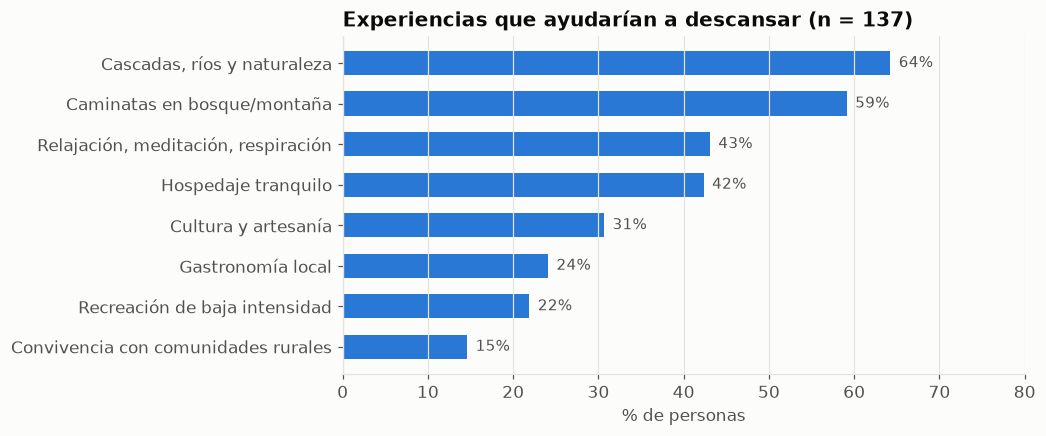

In [7]:
prev = df[PREFERENCIAS].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([ETIQUETAS_PREF[p] for p in prev.index], prev.values * 100, color=SERIES[0], height=0.6)
for i, v in enumerate(prev.values):
    ax.text(v * 100 + 1, i, f'{v:.0%}', va='center', color=TEXTO_2, fontsize=10)
ax.set_xlim(0, 80); ax.set_xlabel('% de personas'); ax.grid(axis='y', visible=False)
ax.set_title(f'Experiencias que ayudarían a descansar (n = {len(df)})')
guardar(fig, '02_preferencias_p10');

## Preferencias por nivel de estrés (terciles, descriptivo)

In [8]:
d = df.dropna(subset=['estres_0_100']).copy()
d['nivel'] = pd.qcut(d['estres_0_100'], 3, labels=['Bajo', 'Medio', 'Alto'])
tabla = (d.groupby('nivel', observed=True)[PREFERENCIAS].mean() * 100).round(0).T
tabla.index = [ETIQUETAS_PREF[p] for p in tabla.index]
print('n por tercil:', d['nivel'].value_counts().sort_index().to_dict())
tabla

n por tercil: {'Bajo': 42, 'Medio': 45, 'Alto': 39}


nivel,Bajo,Medio,Alto
"Cascadas, ríos y naturaleza",62.0,64.0,69.0
Caminatas en bosque/montaña,62.0,62.0,54.0
"Relajación, meditación, respiración",26.0,44.0,59.0
Hospedaje tranquilo,31.0,49.0,46.0
Cultura y artesanía,24.0,36.0,38.0
Gastronomía local,17.0,29.0,28.0
Recreación de baja intensidad,19.0,22.0,26.0
Convivencia con comunidades rurales,17.0,18.0,13.0


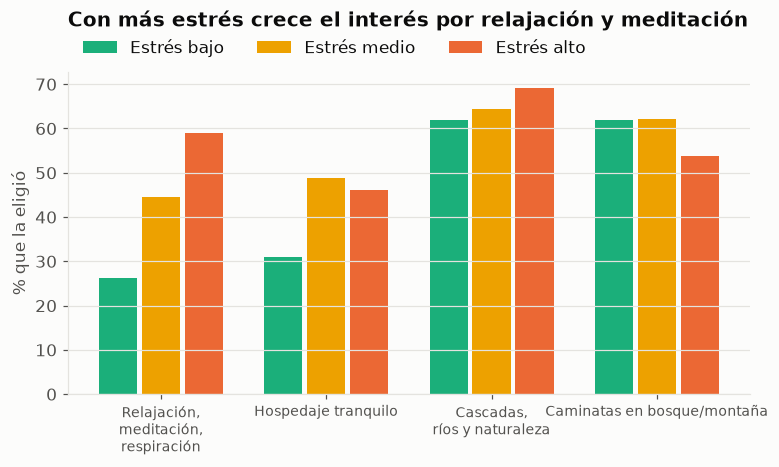

In [9]:
orden = ['pref_relajacion', 'pref_hospedaje_tranquilo', 'pref_cascadas_rios', 'pref_caminatas']
t = d.groupby('nivel', observed=True)[orden].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ancho = 0.26
for j, nivel in enumerate(t.index):
    ax.bar(np.arange(len(orden)) + (j - 1) * ancho, t.loc[nivel], width=ancho - 0.03,
           color=SERIES[[2, 3, 1][j]], label=f'Estrés {nivel.lower()}')
ax.set_xticks(np.arange(len(orden)), [ETIQUETAS_PREF[p].replace(', ', ',\n') for p in orden], fontsize=9)
ax.set_ylabel('% que la eligió'); ax.grid(axis='x', visible=False); ax.legend(frameon=False, ncols=3, loc='lower left', bbox_to_anchor=(0, 1.0)); ax.set_title('Con más estrés crece el interés por relajación y meditación', pad=30)
guardar(fig, '02_preferencias_por_estres');